# Assignment 1E.2: CAVI

This notebook accompanies Section 1.2 of Assignment 1E, 2026. Consider the Normal-Gamma model in Bishop, Equations (10.21)-(10.23), shown below. Here both the mean $\mu$ and the noise precision $\tau$ are unknown.

Use NumPy and SciPy for the numerical implementation and Matplotlib for plots; do not use torch. Do not change the seeds.

**Submission.** Submit your completed notebooks and any supporting source files in two clearly labelled versions: one with comments and one without comments. Both versions must contain the same executable code and produce the same results. Remove only comments from the second version. We will use the version without comments during the oral exam, where you will explain your implementation. Include the commented code in the report appendix.

Complete the functions marked with `NotImplementedError`; that exception is a placeholder for your implementation.

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from scipy.stats import norm, gamma
from scipy.special import psi, gammaln

np.random.seed(0)  # Do not change the seeds
random.seed(0)

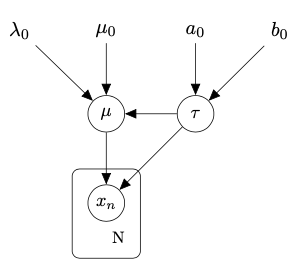

### Question 1.2.5:

Implement a function that generates data points for the given model.

In [2]:
def generate_data(mu, tau, N):
    # Return N Gaussian observations with mean mu and precision tau.
    return np.random.normal(mu, 1/np.sqrt(tau), N)

Set $\mu=1$ and $\tau=0.5$. Generate datasets of size $N=10,100,1000$ and plot a histogram for each dataset.

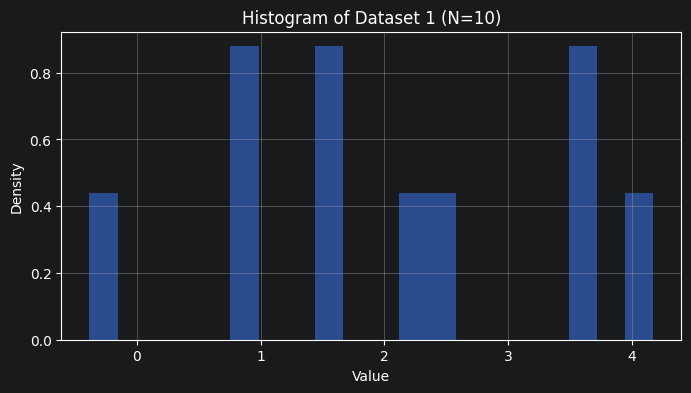

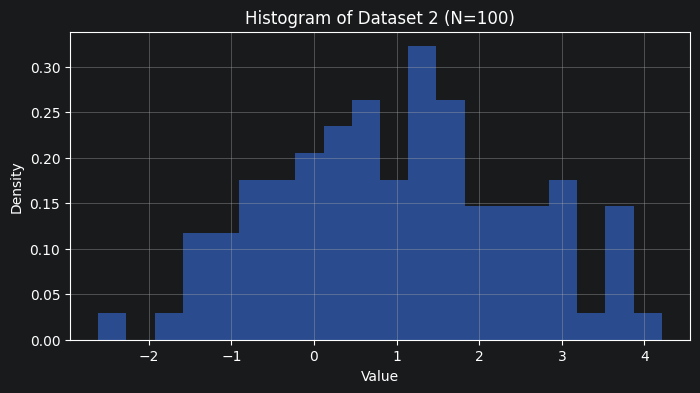

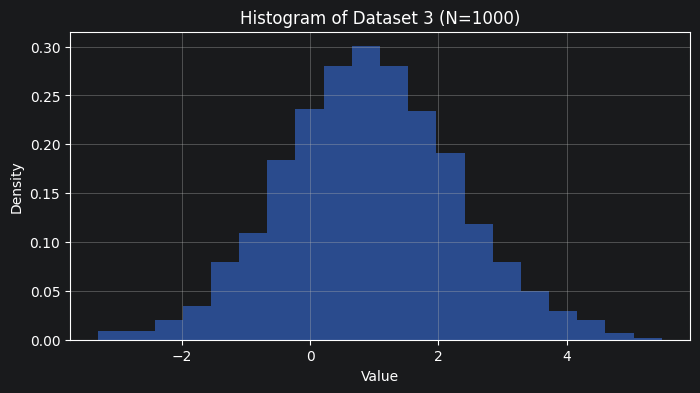

In [3]:
mu = 1
tau = 0.5

dataset_1 = generate_data(mu, tau, 10)
dataset_2 = generate_data(mu, tau, 100)
dataset_3 = generate_data(mu, tau, 1000)
datasets = [dataset_1, dataset_2, dataset_3]

# Visualize the datasets via histograms
# Insert your code here
for i, dataset in enumerate(datasets):
    plt.figure(figsize=(8, 4))
    plt.hist(dataset, bins=20, density=True, alpha=0.6)
    plt.title(f'Histogram of Dataset {i+1} (N={len(dataset)})')
    plt.xlabel('Value')
    plt.ylabel('Density')
    plt.grid()
    plt.show()

### Question 1.2.6:

Write out the expressions for the ML estimates of μ and τ, and implement a function that computes them from data.

In [11]:
def ML_est(data):
    # Return the ML estimates of the mean and precision.
    N = len(data)
    mu_ML = np.mean(data)
    tau_ML = N / (np.sum((data - mu_ML) ** 2))
    return mu_ML, tau_ML

### Question 1.2.7:

What is the exact posterior? First derive it in closed form, and then implement a function that computes its parameters:

In [12]:
def compute_exact_posterior(D, a_0, b_0, mu_0, lambda_0):
    # Return (a_post, b_post, mu_post, lambda_post), using the Gamma rate parameterisation.
    N = len(D)
    mu_post = (lambda_0 * mu_0 + N * np.mean(D)) / (lambda_0 + N)
    lambda_post = lambda_0 + N
    a_post = a_0 + N / 2
    b_post = b_0 + 0.5 * (lambda_0 * mu_0**2 + np.sum(np.square(D)) - lambda_post * mu_post**2)
    return a_post, b_post, mu_post, lambda_post

### Question 1.2.8:

Implement CAVI for the mean-field distribution in Bishop, Equation (10.24). Use the prior parameters below.

In [23]:
# Prior parameters
mu_0 = 0.0
lambda_0 = 1.0
a_0 = 1.0
b_0 = 1.0

def q_mu(D, lambda_0, mu_0, a, b):
    # Return the mean and precision of the variational distribution q(mu).
    N = len(D)
    lambda_n = (lambda_0 + N) * (a / b)
    mu_n = (lambda_0 * mu_0 + N * np.mean(D)) / (lambda_0 + N)
    return mu_n, lambda_n

def q_tau(D, lambda_0, mu_0, a, b, a_0, b_0):
    # Return the mean and precision of the variational distribution q(tau).
    D = np.asarray(D)
    mu_n, lambda_n = q_mu(D, lambda_0, mu_0, a, b)
    a_n = a_0 + (D.size + 1) / 2
    b_n = b_0 + 0.5 * (np.sum((D - mu_n)**2)+ lambda_0 * (mu_n - mu_0)**2+ (D.size + lambda_0) / lambda_n)
    return a_n, b_n

Continue with a helper function that computes the ELBO:

In [24]:
def compute_elbo(D, a_0, b_0, mu_0, lambda_0, a_N, b_N, mu_N, lambda_N):
    # Compute the ELBO for the variational approximation.
    N = len(D)
    # Compute the expected log likelihood
    v = 1 / lambda_N
    Esq = np.sum(np.square(D)) - 2 * mu_N * np.sum(D) + N * (mu_N**2 + v)
    expected_log_likelihood = N/2 * (psi(a_N) - np.log(b_N) - np.log(2*np.pi)) - 0.5 * (a_N/b_N) * Esq

    #Compute the expected log prior for mu
    expected_log_prior_mu = 0.5*np.log(lambda_0/(2*np.pi)) + 0.5*(psi(a_N)-np.log(b_N)) - 0.5 * (a_N/b_N) * lambda_0 * (v + (mu_N - mu_0)**2)

    # Compute the expected log prior for tau
    expected_log_prior_tau = a_0*np.log(b_0) - gammaln(a_0) + (a_0-1)*(psi(a_N) - np.log(b_N)) - b_0*(a_N/b_N)

    # Compute the entropy of q(mu)

    entropy_q_mu = 0.5 * (1 + np.log(2*np.pi) - np.log(lambda_N))

    # Compute the entropy of q(tau)
    entropy_q_tau = a_N - np.log(b_N) + gammaln(a_N) + (1 - a_N) * psi(a_N)
    
    # Compute the ELBO
    elbo = expected_log_likelihood + expected_log_prior_mu + expected_log_prior_tau + entropy_q_mu + entropy_q_tau
    return elbo

Now, implement the CAVI algorithm:

In [34]:
def CAVI(D, a_0, b_0, mu_0, lambda_0):
    # Initialise E[tau], alternate the factor updates and record the ELBO. Return a_N, b_N, mu_N, lambda_N, elbos.
    N = len(D)
    # Initialise the variational parameters
    # Initialize a and b with the prior parameters
    a_N = a_0
    b_N = b_0
    mu_N, lambda_N = q_mu(D, lambda_0, mu_0, a_0, b_0)
    elbos = []

    for i in range(30):
        # Update q(tau)w
        a_N, b_N = q_tau(D, lambda_0, mu_0, a_N, b_N,a_0,b_0)
        # Update q(mu)
        mu_N, lambda_N = q_mu(D, lambda_0, mu_0, a_N, b_N)
        # Compute the ELBO
        elbo = compute_elbo(D, a_0, b_0, mu_0, lambda_0, a_N, b_N, mu_N, lambda_N)
        elbos.append(elbo)
    return a_N, b_N, mu_N, lambda_N, elbos

Run the VI algorithm on the datasets. Compare the inferred variational distribution with the exact posterior and the ML estimate. Visualize the results and discuss your findings.

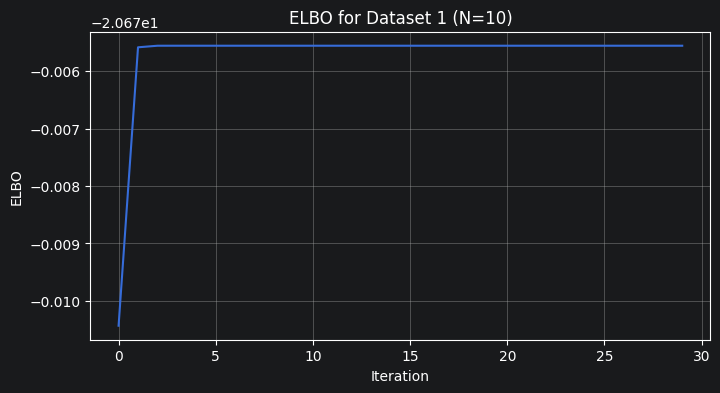

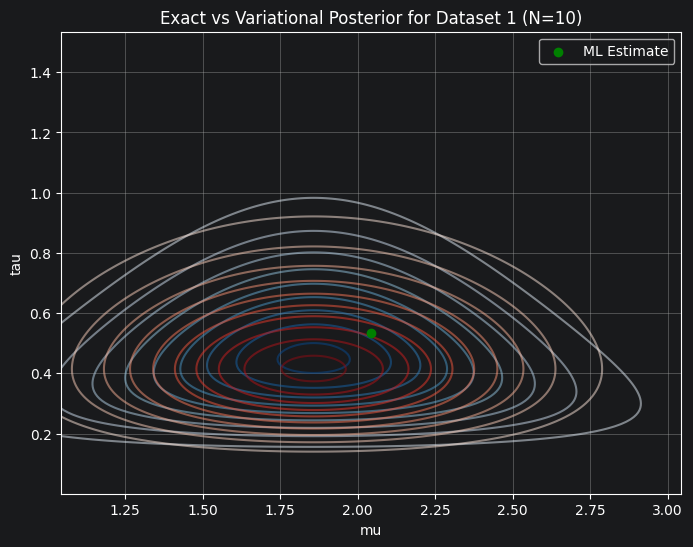

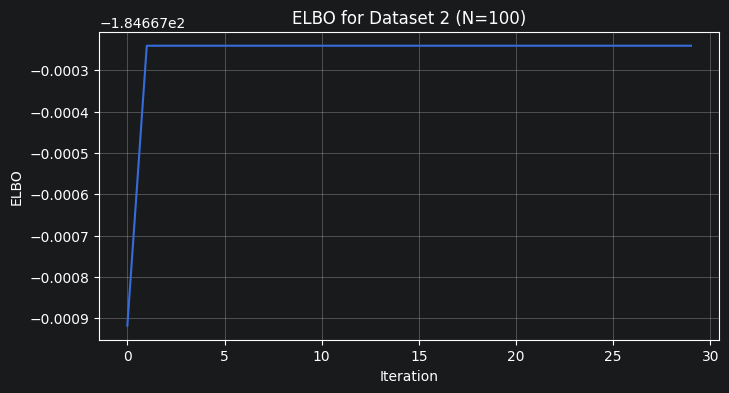

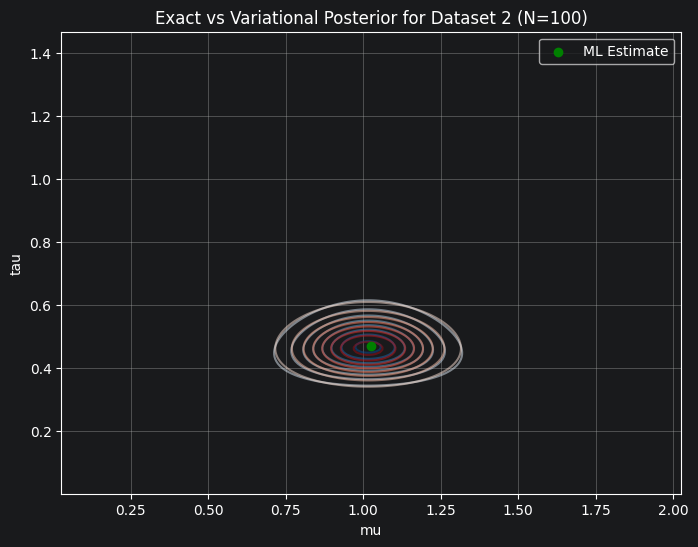

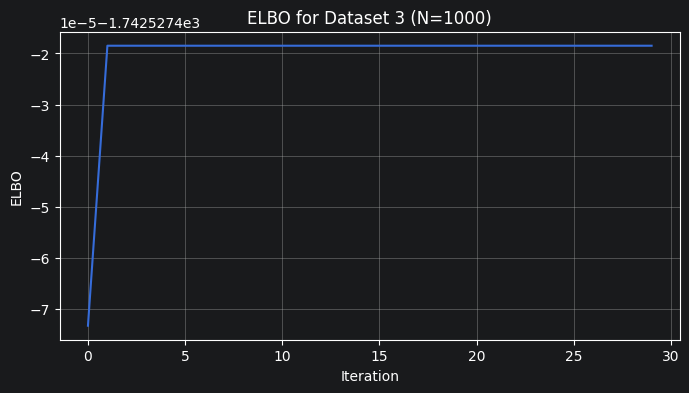

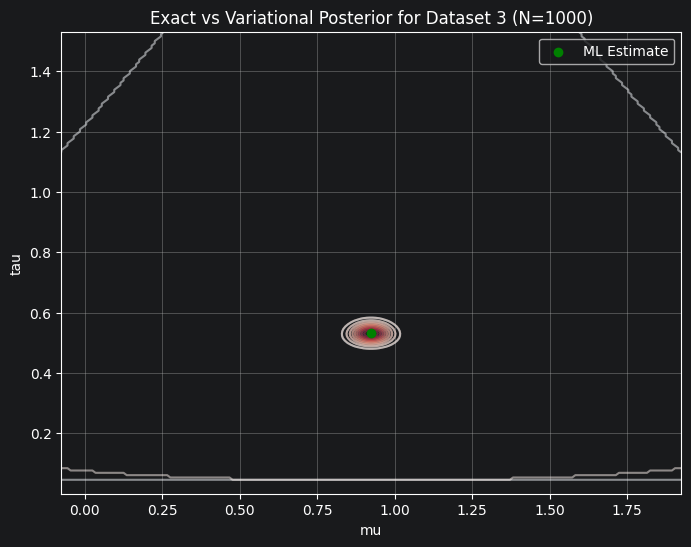

In [36]:
# Run CAVI for each dataset. Plot the ELBO, compare the exact and variational
# joint densities using contours, and mark the ML estimate on the same plot.

for i, dataset in enumerate(datasets):
    a_N, b_N, mu_N, lambda_N, elbos = CAVI(dataset, a_0, b_0, mu_0, lambda_0)
    mu_ML, tau_ML = ML_est(dataset)
    a_post, b_post, mu_post, lambda_post = compute_exact_posterior(dataset, a_0, b_0, mu_0, lambda_0)


    # Plot the ELBO
    plt.figure(figsize=(8, 4))
    plt.plot(elbos)
    plt.title(f'ELBO for Dataset {i+1} (N={len(dataset)})')
    plt.xlabel('Iteration')
    plt.ylabel('ELBO')
    plt.grid()
    plt.show()

    # Create a grid for contour plots
    # mu_range = np.linspace(mu_ML - 3/np.sqrt(tau_ML), mu_ML + 3/np.sqrt(tau_ML), 100)
    # tau_range = np.linspace(0.01, 5 * tau_ML, 100)
    # MU, TAU = np.meshgrid(mu_range, tau_range)

    E_tau = a_post / b_post
    mu_range = np.linspace(mu_ML-1,mu_ML+1, 200)
    tau_range = np.linspace(10**(-5), tau_ML+1, 200)
    MU, TAU = np.meshgrid(mu_range, tau_range)

    # Compute the exact posterior density
    exact_density = (gamma.pdf(TAU, a_post, scale=1/b_post)* norm.pdf(MU,loc=mu_post,scale=1/np.sqrt(lambda_post * TAU)))
    exact_density = exact_density.reshape(MU.shape)

    # Compute the variational posterior density
    variational_density = (gamma.pdf(TAU, a_N, scale=1/b_N)* norm.pdf(MU,loc=mu_N,scale=1/np.sqrt(lambda_N)))
    variational_density = variational_density.reshape(MU.shape)

    # Plot the contours
    plt.figure(figsize=(8, 6))
    plt.contour(MU, TAU, exact_density, levels=10, cmap='Blues', alpha=0.5)
    plt.contour(MU, TAU, variational_density, levels=10, cmap='Reds', alpha=0.5)
    plt.scatter(mu_ML, tau_ML, color='green', label='ML Estimate', zorder=5)

    plt.title(f'Exact vs Variational Posterior for Dataset {i+1} (N={len(dataset)})')
    plt.xlabel('mu')
    plt.ylabel('tau')
    plt.legend()
    plt.grid()
    plt.show()

*Your discussion here.*